# 05 · Prueba en 2025

Con la decisión ya registrada (notebook 04), la versión elegida y, como referencia, las demás candidatas se ajustan con todo 2023–2024 y se califican en 2025 (`src/05_prueba_2025.py`, que se niega a correr sin `decision.json`). Aquí se muestran sus resultados; no se reentrena nada.

- **Población de prueba:** desembolsos de enero a junio de 2025 con resultado a 6 meses (1.033 créditos, 93 eventos de 30+); los pagos anticipados cuentan como buenos pagadores.
- **Referencia:** el segmento actual (Bronce/Plata/Oro), que no entra a ningún modelo.
- **Pruebas confirmatorias** (corregidas con Holm): elegida frente al segmento; elegida frente a la mejor en validación cruzada; costo de quitar el sexo. Todo lo demás es exploratorio.

In [1]:
import json, sys, importlib.util, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import protocolo as P
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 200); pd.set_option("display.float_format", "{:,.4f}".format)
R, R25, DG = P.SALIDA, P.SALIDA / "reporte_2025", P.SALIDA / "diagnosticos"
leer = lambda r: pd.read_csv(r, encoding="utf-8-sig")
def script(nombre):
    spec = importlib.util.spec_from_file_location(nombre.replace(".py", ""), RAIZ / "src" / nombre)
    m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m); return m
NOMBRE = {"C1_completo": "C1 · Completo (17)", "C2_seleccionado": "C2 · Seleccionado (12)",
          "C3_V2p": "C3 · Depurado (6)", "C4_V2p_compra": "C4 · C3 + compra fuera del depto. (7)",
          "C5_V3p": "C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9)", "C6_V5p": "C6 · C5 + departamento (10)",
          "A_C3_con_sexo": "C3 + sexo (7)", "segmento": "Segmento actual"}
import utilidades_auc as U
decision = json.loads(P.DECISION.read_text(encoding="utf-8")); ELEGIDA = decision["version"]
print("Versión elegida:", NOMBRE[ELEGIDA], "|", ", ".join(decision["variables"]))

Versión elegida: C3 · Depurado (6) | edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto


## 1. Discriminación y detección en 2025 (30+ a 6 meses)

In [2]:
d = leer(R25 / "discriminacion_30_6m.csv")
d.insert(0, "versión", d.version.map(NOMBRE))
d[["versión", "n", "eventos", "auc", "auc_ic_inf", "auc_ic_sup", "ks", "tasa_deteccion_10", "td_ic_inf_10", "td_ic_sup_10",
   "tasa_deteccion_20", "td_ic_inf_20", "td_ic_sup_20"]]

,versión,n,eventos,auc,auc_ic_inf,auc_ic_sup,ks,tasa_deteccion_10,td_ic_inf_10,td_ic_sup_10,tasa_deteccion_20,td_ic_inf_20,td_ic_sup_20
0,C1 · Completo (17),1033,93,0.6333,0.5707,0.6959,0.2192,0.2151,0.1437,0.3090,0.3871,0.2945,0.4887
1,C3 · Depurado (6),1033,93,0.6197,0.5562,0.6832,0.2070,0.2151,0.1437,0.3090,0.3763,0.2846,0.4779
2,C4 · C3 + compra fuera del depto. (7),1033,93,0.6220,0.5577,0.6864,0.2157,0.2258,0.1527,0.3207,0.3763,0.2846,0.4779
3,C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9),1033,93,0.6351,0.5726,0.6977,0.2512,0.2366,0.1617,0.3323,0.3978,0.3043,0.4995
4,C6 · C5 + departamento (10),1033,93,0.6343,0.5719,0.6968,0.2344,0.2258,0.1527,0.3207,0.3763,0.2846,0.4779
5,C2 · Seleccionado (12),1033,93,0.6287,0.5654,0.6920,0.2225,0.2258,0.1527,0.3207,0.3656,0.2749,0.4670
6,C3 + sexo (7),1033,93,0.6366,0.5747,0.6985,0.2321,0.2258,0.1527,0.3207,0.3978,0.3043,0.4995
7,Segmento actual,1033,93,0.5262,0.4922,0.5601,0.0477,NaN,NaN,NaN,NaN,NaN,NaN


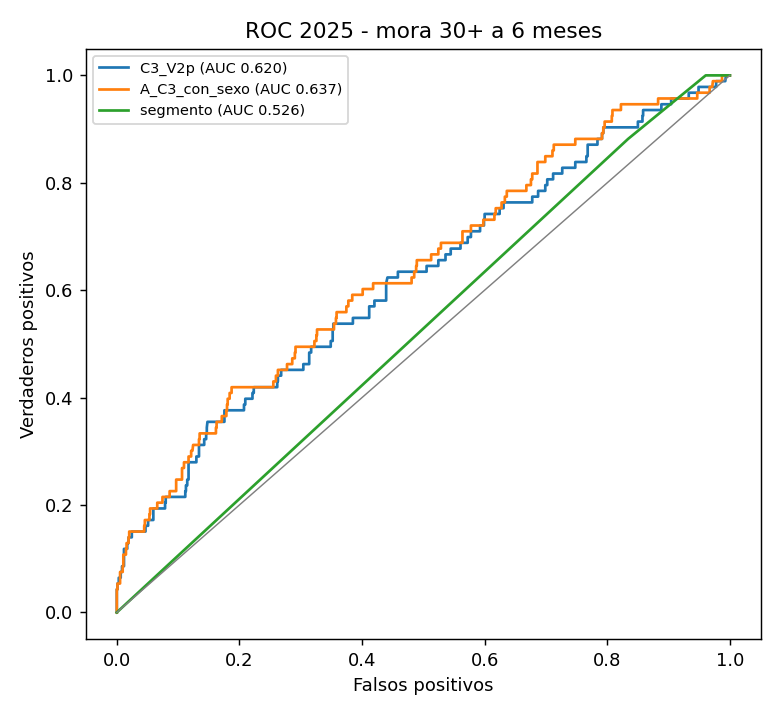

In [3]:
display(Image(str(R25 / "roc_2025.png")))

## 2. Pruebas confirmatorias (Holm)

In [4]:
leer(R25 / "pruebas_confirmatorias.csv")

,prueba,p,p_holm
0,C3_V2p frente al segmento actual (2025),0.0130,0.0390
1,C3_V2p frente a la mejor en CV (C2_seleccionado),0.2460,0.4920
2,pérdida por quitar el sexo (CV),0.7196,0.7196


## 3. Comparaciones exploratorias

In [5]:
dif = leer(R25 / "diferencias_vs_elegida.csv"); dif.insert(0, "versión", dif.version.map(NOMBRE)); dif

,versión,version,frente_a,diferencia,ic_delong_inf,ic_delong_sup,ic_boot_inf,ic_boot_sup,p
0,C1 · Completo (17),C1_completo,C3_V2p,0.0136,-0.0115,0.0387,-0.0107,0.0417,0.2882
1,C4 · C3 + compra fuera del depto. (7),C4_V2p_compra,C3_V2p,0.0024,-0.0068,0.0115,-0.0058,0.0123,0.6125
2,C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9),C5_V3p,C3_V2p,0.0155,-0.0014,0.0323,-0.0005,0.0338,0.0721
3,C6 · C5 + departamento (10),C6_V5p,C3_V2p,0.0146,-0.0059,0.0351,-0.0051,0.0374,0.1614
4,C2 · Seleccionado (12),C2_seleccionado,C3_V2p,0.0091,-0.0185,0.0366,-0.0180,0.0380,0.5198
5,C3 + sexo (7),A_C3_con_sexo,C3_V2p,0.0169,0.0056,0.0283,0.0058,0.0275,0.0035
6,Segmento actual,segmento,C3_V2p,-0.0935,-0.1673,-0.0197,-0.1638,-0.0269,0.0130


In [6]:
# Cada versión frente al segmento actual, en los cuatro objetivos (exploratorio, sin corrección)
s = pd.read_parquet(R25 / "puntajes_2025.parquet")
filas = []
for obj in ["mora30_6m", "mora30_3m", "mora60_6m", "mora90_6m"]:
    col = f"{obj}__{P.ETIQUETA}"
    t = s[s[col].notna() & s["score__segmento"].notna()]
    y = t[col].astype(int).values
    for v in [ELEGIDA] + [c for c in list(P.candidatas()) + ["A_C3_con_sexo"] if c != ELEGIDA]:
        a1, a2, dd, ee, i1, i2, p = U.delong(y, t[f"score__{v}"].values, t["score__segmento"].values)
        filas.append({"objetivo": obj, "versión": NOMBRE[v], "n": len(y), "eventos": int(y.sum()), "AUC": a1,
                      "AUC segmento": a2, "diferencia": dd, "IC inf": i1, "IC sup": i2, "p": p})
pd.DataFrame(filas)

,objetivo,versión,n,eventos,AUC,AUC segmento,diferencia,IC inf,IC sup,p
0,mora30_6m,C3 · Depurado (6),1033,93,0.6197,0.5262,0.0935,0.0197,0.1673,0.0130
1,mora30_6m,C1 · Completo (17),1033,93,0.6333,0.5262,0.1071,0.0332,0.1810,0.0045
2,mora30_6m,C4 · C3 + compra fuera del depto. (7),1033,93,0.6220,0.5262,0.0959,0.0208,0.1710,0.0123
3,mora30_6m,C5 · C4 + frecuencia de ciudad + volumen del distribuidor (9),1033,93,0.6351,0.5262,0.1090,0.0350,0.1829,0.0039
4,mora30_6m,C6 · C5 + departamento (10),1033,93,0.6343,0.5262,0.1082,0.0353,0.1810,0.0036
5,mora30_6m,C2 · Seleccionado (12),1033,93,0.6287,0.5262,0.1026,0.0295,0.1756,0.0059
6,mora30_6m,C3 + sexo (7),1033,93,0.6366,0.5262,0.1104,0.0383,0.1825,0.0027
7,mora30_3m,C3 · Depurado (6),1885,73,0.6943,0.5466,0.1477,0.0773,0.2182,0.0000
8,mora30_3m,C1 · Completo (17),1885,73,0.7040,0.5466,0.1574,0.0854,0.2293,0.0000
9,mora30_3m,C4 · C3 + compra fuera del depto. (7),1885,73,0.7010,0.5466,0.1544,0.0828,0.2261,0.0000


**Lectura:**
- La versión elegida (C3) tiene en 2025 un **AUC de 0,620** [0,556; 0,683] en 30+ a 6 meses, frente a 0,526 del segmento actual: **+0,094 [+0,020; +0,167], p = 0,013**. Con la corrección de Holm sobre las tres pruebas confirmatorias, la diferencia sigue siendo significativa al 5 % (p = 0,039).
- Con el **mismo puntaje**, la ventaja es mayor en las demás definiciones del evento: **30+ a 3 meses 0,694 frente a 0,547 (p < 0,001)**, **60+ 0,665 frente a 0,524 (p = 0,002)** y **90+ 0,714 frente a 0,531 (p < 0,001)**. El objetivo de 6 meses es el que C3 ordena con menor AUC, lo que es coherente con que incluya deterioros tardíos (meses 4 a 6), más alejados de la información de la solicitud.
- **Detección:** marcando el 20 % de mayor puntaje, C3 captura el **37,6 %** de los eventos de 2025 [28,5; 47,8]; marcando el 10 %, el 21,5 % [14,4; 30,9].
- En esta prueba, las versiones con más variables obtienen AUC más altos que C3 (C5: +0,015, p = 0,072; C6: +0,015, p = 0,161; C1: +0,014, p = 0,288), sin que ninguna diferencia se distinga de cero; son comparaciones exploratorias. La versión con sexo obtiene +0,017 [+0,006; +0,028] (p = 0,003), que se discute en la sección 6 y en el notebook 07. **Nada de esto cambia la decisión:** el protocolo prohíbe escoger con 2025, y en validación cruzada esas versiones no se distinguieron de C3.

## 4. Calibración por año

In [7]:
leer(R25 / "calibracion_por_anio.csv")

,periodo,fuente,tasa_observada,prob_media,brier,brier_constante,pendiente_cal,intercepto_cal,desplazamiento_logit
0,2023,CV (OOF),0.3485,0.2387,0.2290,0.2270,1.2705,0.8629,NaN
1,2024,CV (OOF),0.1863,0.2290,0.1436,0.1516,1.4168,0.2067,NaN
2,2025,prueba,0.0900,0.2121,0.0939,0.0819,1.3191,-0.6415,NaN
3,2025-T2,prueba sin recalibrar,0.0768,0.2101,0.0861,0.0709,1.4762,-0.6119,NaN
4,2025-T2,prueba recalibrada con 2025-T1,0.0768,0.1015,0.0686,0.0709,1.4762,0.6801,-0.8753


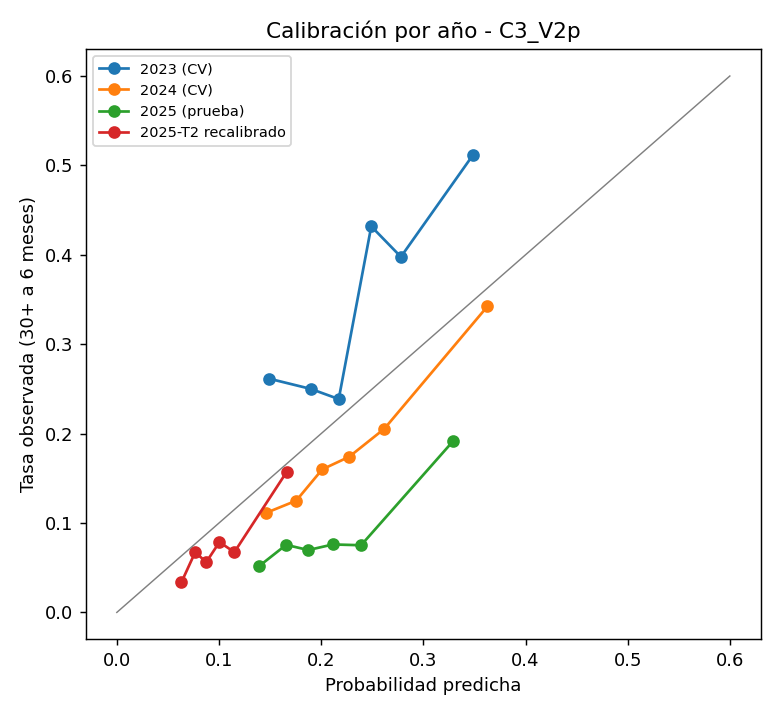

In [8]:
display(Image(str(R25 / "calibracion_por_anio.png")))

**Lectura:**
- El **orden** se conserva en los tres años: la pendiente de calibración es **1,27 (2023), 1,42 (2024) y 1,32 (2025)**, siempre mayor que 1, sin el patrón de sobreajuste (pendiente < 1).
- El **nivel** no se conserva: el modelo predice en promedio 21,2 % en 2025 frente a una mora observada de 9,0 %, porque la mora cayó con fuerza entre cosechas (notebook 06). Sin recalibrar, el Brier de 2025 (0,094) es peor que el de una constante (0,082).
- **Recalibrando solo el intercepto** con 2025-T1, el nivel de 2025-T2 pasa a 10,2 % frente a 7,7 % observado y el Brier baja de 0,086 a 0,069, por debajo del de una constante (0,071). En producción, el nivel debe recalibrarse periódicamente con la cosecha madura más reciente.

## 5. Monitoreo a 3 meses y confirmación con 60+ y 90+ (mismo puntaje)

In [9]:
m = leer(R25 / "monitoreo_confirmacion.csv"); m.insert(1, "versión", m.version.map(NOMBRE)); m[m.objetivo != "mora30_6m"]

,objetivo,versión,grupo,version,n,eventos,auc,ic_inf,ic_sup
0,mora30_3m,C3 · Depurado (6),todos,C3_V2p,1885,73,0.6943,0.6308,0.7579
1,mora30_3m,C3 + sexo (7),todos,A_C3_con_sexo,1885,73,0.6999,0.6372,0.7625
2,mora30_3m,Segmento actual,todos,segmento,1885,73,0.5466,0.5171,0.5761
3,mora30_3m,C3 · Depurado (6),ene-jun 2025,C3_V2p,1033,44,0.6806,0.5923,0.7689
4,mora30_3m,C3 + sexo (7),ene-jun 2025,A_C3_con_sexo,1033,44,0.6920,0.6043,0.7796
5,mora30_3m,Segmento actual,ene-jun 2025,segmento,1033,44,0.5387,0.4956,0.5817
6,mora30_3m,C3 · Depurado (6),jul-sep 2025,C3_V2p,852,29,0.7138,0.6242,0.8033
7,mora30_3m,C3 + sexo (7),jul-sep 2025,A_C3_con_sexo,852,29,0.7115,0.6241,0.7989
8,mora30_3m,Segmento actual,jul-sep 2025,segmento,852,29,0.5597,0.5246,0.5949
9,mora60_6m,C3 · Depurado (6),todos,C3_V2p,1033,58,0.6653,0.5901,0.7404


**Lectura:** el puntaje de 30+ a 6 meses ordena **mejor** los deterioros tempranos y severos: 0,694 en 30+ a 3 meses (0,681 en enero-junio y 0,714 en julio-septiembre de 2025), 0,665 en 60+ y 0,714 en 90+. La ventana de 3 meses sirve para vigilar el modelo con cosechas recientes sin esperar 6 meses.

## 6. Auditoría de equidad por sexo

In [10]:
eq = leer(R25 / "equidad_sexo_2025.csv"); eq.insert(0, "versión", eq.version.map(NOMBRE)); eq

,versión,version,sexo,n,eventos,tasa_observada,prob_media,observado_sobre_esperado,auc_dentro_del_sexo,pct_marcados_10,tpr_10,tpr_10_ic_inf,tpr_10_ic_sup,fpr_10,pct_marcados_20,tpr_20,tpr_20_ic_inf,tpr_20_ic_sup,fpr_20
0,C3 · Depurado (6),C3_V2p,F,415.0000,21.0000,0.0506,0.2073,0.2441,0.6166,0.0843,0.1905,0.0767,0.4000,0.0787,0.1735,0.3810,0.2075,0.5912,0.1624
1,C3 · Depurado (6),C3_V2p,M,618.0000,72.0000,0.1165,0.2152,0.5413,0.6129,0.1117,0.2222,0.1417,0.3309,0.0971,0.2184,0.3750,0.2722,0.4905,0.1978
2,C3 · Depurado (6),C3_V2p,AUC del puntaje para separar sexos,NaN,NaN,NaN,NaN,NaN,0.5357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C3 + sexo (7),A_C3_con_sexo,F,415.0000,21.0000,0.0506,0.1934,0.2616,0.6161,0.0627,0.1905,0.0767,0.4000,0.0558,0.1325,0.3333,0.1719,0.5463,0.1218
4,C3 + sexo (7),A_C3_con_sexo,M,618.0000,72.0000,0.1165,0.2226,0.5234,0.6119,0.1294,0.2361,0.1530,0.3460,0.1154,0.2460,0.4167,0.3099,0.5319,0.2234
5,C3 + sexo (7),A_C3_con_sexo,AUC del puntaje para separar sexos,NaN,NaN,NaN,NaN,NaN,0.6462,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Lectura** (2025, C3 sin sexo frente a la versión con sexo):
- **Marcado y falsos positivos:** con C3, al marcar el 20 % de mayor puntaje se marca al **17,3 % de las mujeres y al 21,8 % de los hombres**, con tasas de falsos positivos de 16,2 % y 19,8 %. Con la versión con sexo se marcaría al 13,3 % de las mujeres y al 24,6 % de los hombres (falsos positivos de 12,2 % y 22,3 %): el sexo movería la decisión.
- **Sin sustituto del sexo:** el puntaje de C3 distingue poco el sexo (AUC 0,536, frente a 0,646 con la versión con sexo). Las demás variables no lo están reemplazando.
- **Costo:** las mujeres tienen menos mora (5,1 % frente a 11,7 %) y su riesgo queda sobreestimado con o sin el sexo (observado/esperado de 0,24 frente a 0,54 con C3, y de 0,26 frente a 0,52 con la versión con sexo). La detección de eventos al 20 % es de 38,1 % en mujeres y 37,5 % en hombres, aunque con 21 eventos de mujeres los intervalos son amplios. La auditoría completa por sexo y estrato, con su familia confirmatoria, está en el notebook 07.

## 7. Deciles de riesgo frente al segmento actual

In [11]:
leer(R25 / "deciles_vs_segmento.csv")

,decil,n,tasa,prob_media,pct_BRONCE,pct_ORO,pct_PLATA
0,1,104,0.1923,0.3641,0.8654,0.0577,0.0769
1,2,103,0.1456,0.2697,0.8835,0.0097,0.1068
2,3,103,0.0680,0.2379,0.7573,0.0583,0.1845
3,4,103,0.0874,0.2202,0.8350,0.0583,0.1068
4,5,103,0.0777,0.2073,0.8738,0.0000,0.1262
5,6,104,0.0673,0.1924,0.8846,0.0385,0.0769
6,7,103,0.0680,0.1778,0.8350,0.0291,0.1359
7,8,103,0.0874,0.1657,0.8252,0.0485,0.1262
8,9,103,0.0583,0.1527,0.8252,0.0291,0.1456
9,10,104,0.0481,0.1323,0.7981,0.0288,0.1731


**Composición del segmento** en la prueba de 2025 (créditos con resultado a 6 meses).

In [12]:
s[s[P.Y].notna()]["ref_segmento"].value_counts().to_frame("créditos").assign(
    proporción=lambda d: d["créditos"] / d["créditos"].sum())

,créditos,proporción
ref_segmento,,
BRONCE,866,0.8383
PLATA,130,0.1258
ORO,37,0.0358


**Lectura:** los dos deciles de mayor puntaje concentran las tasas más altas (19,2 % y 14,6 %, frente a 9,0 % en promedio), y el segmento actual es Bronce en el 75,7 % al 88,5 % de cada decil (83,8 % en total): el modelo separa riesgo que el segmento no ve. El orden no es monótono en los deciles intermedios, coherente con un AUC moderado y una muestra de 93 eventos.